# Финальная модель — Левин
Итог работы из [model_levin.ipynb](model_levin.ipynb) и [clients_levin.ipynb](clients_levin.ipynb): финальная конфигурация и **честная оценка на финальном hold-out**.

**Конфигурация**
- **Модель:** один LightGBM (мелкие деревья), без ансамблей, без взвешивания классов и сэмплинга (ранжирование не улучшают, калибровку портят).
- **Признаки:** без `duration` (утечка), без прокси периода (`month`, `day`, `contact`, `contact_unknown`), без года, **без `campaign`** (формально «из будущего»); плюс **история клиента на момент звонка** (число прошлых покупок, флаг «покупал», дней с последней покупки, глубина цепочки).

**Схема оценки (финальная)**
- **Train:** всё до 2009-05 включительно — период массового обзвона (много контактов, низкая конверсия).
- **Hold-out (test):** 2009-06 … 2010-11 — период точечного обзвона (мало контактов, высокая конверсия). Это самая жёсткая проверка: учимся на одном режиме, работаем в другом.
- **Гиперпараметры подбираем только на train** (time split внутри train), test не трогаем до финальной оценки.
- Метрики на test: AUC, PR-AUC, Precision и Lift в топ-10% с bootstrap-интервалом. Абсолютную Precision и PR-AUC сравнивать с другими периодами нельзя: база сильно дрейфует.

## 0. Данные и дрейф

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve, brier_score_loss
from sklearn.isotonic import IsotonicRegression
import utils_levin as ul
sns.set_theme(style='whitegrid'); pd.set_option('display.width', 140, 'display.max_columns', 40)

raw, y, year, period = ul.load(); n = len(y)
X_old = ul.build(raw, drop=ul.NP_DROP)                 # прежний набор (с campaign, без истории)
X = ul.final_features(raw, year, y)                    # финальный набор
hist = (X.h_depth > 0).values

drift = pd.DataFrame({'year': year, 'y': y, 'per': period, 'hist': hist}).groupby('year').agg(
    строк=('y', 'size'), месяцев=('per', 'nunique'), конверсия=('y', 'mean'), доля_с_историей=('hist', 'mean'))
drift['строк в месяц'] = (drift['строк'] / drift['месяцев']).round(0)
display(drift.round(3))

,строк,месяцев,конверсия,доля_с_историей,строк в месяц
year,,,,,
2008,27729,7,0.051,0.029,3961.0
2009,14862,12,0.171,0.322,1238.0
2010,2620,11,0.516,0.545,238.0


Режим обзвона резко меняется: в 2008 массовые звонки (≈ 4 тыс. в месяц, конверсия 5%), в 2010 точечные (≈ 240 в месяц, конверсия 52%), доля клиентов с историей растёт с 3% до 55%. Даже среди клиентов без прошлой кампании конверсия растёт (5% → 17% → 46%), то есть это не только смена состава. Причину данные не раскрывают (отбор клиентов банком или выборка авторов датасета).

## 1. Разбиение: train до 2009-05, hold-out после

In [2]:
cut = int(np.argmax(period >= 200906)); tr = np.arange(cut); te = np.arange(cut, n)
yt = y[te]
print(f'train: {len(tr)} строк (до 2009-05), конверсия {y[tr].mean():.3f}, с историей {hist[tr].mean():.1%}')
print(f'test : {len(te)} строк (2009-06…2010-11), конверсия {yt.mean():.3f}, с историей {hist[te].mean():.1%}')

train: 39752 строк (до 2009-05), конверсия 0.071, с историей 11.4%
test : 5459 строк (2009-06…2010-11), конверсия 0.455, с историей 45.6%


## 2. Подбор гиперпараметров — только на train
Random search (25 конфигураций + прежние параметры) с валидацией по времени **внутри train** (forward-chaining, 5 фолдов). Критерий — средний AUC по фолдам. Test здесь не используется.

In [3]:
rng = np.random.default_rng(ul.SEED); Xtr, ytr = X.iloc[tr], y[tr]; sp_in = ul.time_splits(len(tr), 5)
grid = dict(num_leaves=[3, 4, 6, 8, 16, 31], n_estimators=[150, 250, 400, 600], learning_rate=[0.01, 0.02, 0.03, 0.05],
            min_child_samples=[20, 50, 100, 200, 400], colsample_bytree=[0.4, 0.5, 0.7, 1.0], reg_lambda=[0, 1, 5, 20], cat_smooth=[10, 50, 100, 200])
cands = [dict(ul.BEST)] + [{k: rng.choice(v).item() for k, v in grid.items()} for _ in range(25)]
rows = []
for i, c in enumerate(cands):
    m = ul.run_cv(lambda X_, c=c: ul.make_lgb(X_, **c), Xtr, ytr, sp_in)[0]
    rows.append({'i': i, 'AUC': m.auc.mean(), 'PR-AUC': m.pr.mean(), 'Lift@10%': m.lift10.mean()})
tune = pd.DataFrame(rows).sort_values('AUC', ascending=False)
display(tune.head(8).round(3).set_index('i'))
best = cands[int(tune.i.iloc[0])]; print('лучшие параметры:', best); print('прежние параметры (i=0): AUC', tune.set_index('i').loc[0, 'AUC'].round(3))

,AUC,PR-AUC,Lift@10%
i,,,
18,0.598,0.121,1.760
0,0.598,0.122,1.718
23,0.598,0.121,1.776
5,0.597,0.123,1.717
1,0.597,0.122,1.718
13,0.596,0.121,1.773
25,0.595,0.119,1.754
22,0.594,0.118,1.726


лучшие параметры: {'num_leaves': 3, 'n_estimators': 250, 'learning_rate': 0.03, 'min_child_samples': 200, 'colsample_bytree': 0.5, 'reg_lambda': 20, 'cat_smooth': 100}
прежние параметры (i=0): AUC 0.598


## 3. Финальная оценка на hold-out
Модель обучается на train, предсказывает test. Bootstrap (300 повторов) даёт 95% интервал. Сравниваем с вариантами: прежние признаки, без истории, прежние параметры.

In [4]:
def metrics(yt, p, f=0.10):
    k = int(len(yt) * f); idx = np.argsort(-p)[:k]
    return dict(AUC=roc_auc_score(yt, p), **{'PR-AUC': average_precision_score(yt, p)}, **{'Precision@10%': yt[idx].mean(), 'Lift@10%': yt[idx].mean() / yt.mean()})

def boot(yt, p, B=300, seed=0):
    r = np.random.default_rng(seed); A, L = [], []
    for _ in range(B):
        i = r.integers(0, len(yt), len(yt)); A.append(roc_auc_score(yt[i], p[i])); k = int(len(i) * .1); L.append(yt[i][np.argsort(-p[i])[:k]].mean() / yt[i].mean())
    return np.percentile(A, [2.5, 97.5]), np.percentile(L, [2.5, 97.5])

def fit_pred(F, params):
    return ul.make_lgb(F, **params).fit(F.iloc[tr], y[tr]).predict_proba(F.iloc[te])[:, 1]

noh = X.drop(columns=[c for c in X.columns if c.startswith('h_')])
variants = {'финальная (признаки с историей, подобранные параметры)': (X, best), 'без истории клиента': (noh, best),
            'прежний набор (с campaign, без истории)': (X_old, best), 'финальные признаки, прежние параметры': (X, ul.BEST)}
P, rows = {}, []
for name, (F, prm) in variants.items():
    P[name] = fit_pred(F, prm); rows.append({'вариант': name, **metrics(yt, P[name])})
res = pd.DataFrame(rows).set_index('вариант'); display(res.round(3))
p = P['финальная (признаки с историей, подобранные параметры)']; ci_a, ci_l = boot(yt, p)
print(f'Финальная модель: AUC {roc_auc_score(yt, p):.3f} (95% ДИ {ci_a[0]:.3f}–{ci_a[1]:.3f}), Lift@10% {metrics(yt, p)["Lift@10%"]:.2f} (95% ДИ {ci_l[0]:.2f}–{ci_l[1]:.2f})')
print(f'максимально возможный Lift@10% при базе {yt.mean():.1%} (топ-10% — все yes): {1 / yt.mean():.2f}')

,AUC,PR-AUC,Precision@10%,Lift@10%
вариант,,,,
"финальная (признаки с историей, подобранные параметры)",0.600,0.553,0.640,1.406
без истории клиента,0.597,0.551,0.642,1.410
"прежний набор (с campaign, без истории)",0.597,0.555,0.628,1.378
"финальные признаки, прежние параметры",0.600,0.554,0.672,1.475


Финальная модель: AUC 0.600 (95% ДИ 0.582–0.614), Lift@10% 1.41 (95% ДИ 1.31–1.49)
максимально возможный Lift@10% при базе 45.5% (топ-10% — все yes): 2.20


## 4. PR-кривая, Precision и Lift по доле топа

,Precision,Lift,Recall
топ 2%,0.679,1.491,0.030
топ 5%,0.676,1.485,0.074
топ 10%,0.640,1.406,0.140
топ 20%,0.582,1.278,0.255
топ 30%,0.562,1.234,0.370
топ 50%,0.532,1.169,0.584


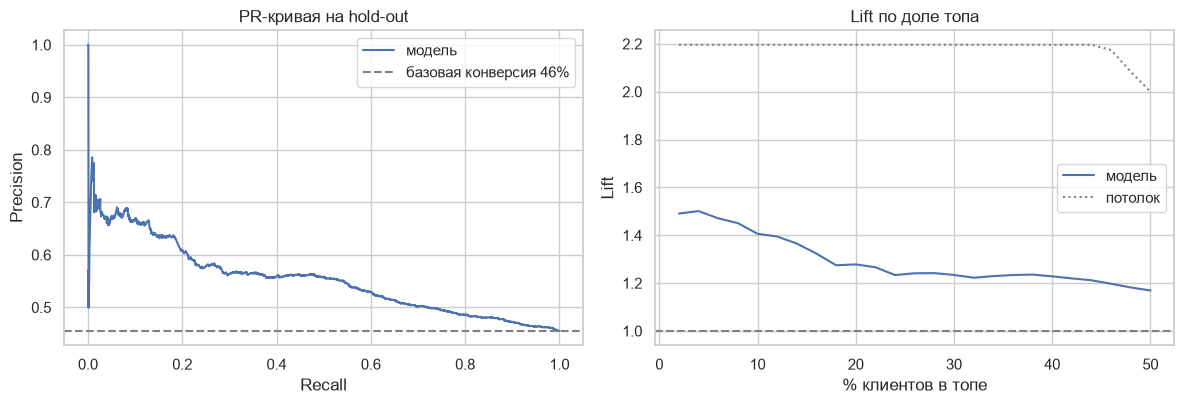

In [5]:
fr = np.array([0.02, 0.05, 0.10, 0.20, 0.30, 0.50])
tab = pd.DataFrame({f'топ {int(f*100)}%': {'Precision': yt[np.argsort(-p)[:int(len(yt)*f)]].mean(), 'Lift': yt[np.argsort(-p)[:int(len(yt)*f)]].mean() / yt.mean(),
                                          'Recall': yt[np.argsort(-p)[:int(len(yt)*f)]].sum() / yt.sum()} for f in fr}).T
display(tab.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
pr, rc, _ = precision_recall_curve(yt, p); ax[0].plot(rc, pr, label='модель'); ax[0].axhline(yt.mean(), ls='--', color='gray', label=f'базовая конверсия {yt.mean():.0%}')
ax[0].set(xlabel='Recall', ylabel='Precision', title='PR-кривая на hold-out'); ax[0].legend()
g = np.linspace(0.02, 0.5, 25); ax[1].plot(g * 100, [yt[np.argsort(-p)[:int(len(yt)*f)]].mean() / yt.mean() for f in g], label='модель')
ax[1].plot(g * 100, [min(f * 1.0, yt.mean()) / f / yt.mean() for f in g], ls=':', color='gray', label='потолок'); ax[1].axhline(1, ls='--', color='gray')
ax[1].set(xlabel='% клиентов в топе', ylabel='Lift', title='Lift по доле топа'); ax[1].legend(); plt.tight_layout(); plt.show()

## 5. По сегментам: клиенты с историей и без

In [6]:
rows = []
for name, mk in [('есть история', hist[te]), ('нет истории', ~hist[te])]:
    ys, ps = yt[mk], p[mk]; rows.append({'сегмент': name, 'строк': mk.sum(), 'доля yes': ys.mean(), **metrics(ys, ps)})
display(pd.DataFrame(rows).set_index('сегмент').round(3))

,строк,доля yes,AUC,PR-AUC,Precision@10%,Lift@10%
сегмент,,,,,,
есть история,2488,0.525,0.654,0.642,0.677,1.292
нет истории,2971,0.398,0.512,0.398,0.374,0.940


## 6. Калибровка и дообучение на свежих данных
Модель учится на периоде с конверсией 7%, а работает на 45%, поэтому вероятности занижены (ранжирование от этого не страдает). Проверяем два способа: изотоническая калибровка и дообучение на свежем куске. Test делим по времени пополам: «свежая» первая половина (калибровка/дообучение) и вторая половина (оценка).

In [7]:
h = len(te) // 2; a, b = te[:h], te[h:]; yb = y[b]
pb = p[h:]                                                                  # модель из train, без калибровки
iso = IsotonicRegression(out_of_bounds='clip').fit(p[:h], y[a]); pc = iso.predict(pb)
tr2 = np.concatenate([tr, a]); pr2 = ul.make_lgb(X, **best).fit(X.iloc[tr2], y[tr2]).predict_proba(X.iloc[b])[:, 1]
rows = []
for name, q in [('train, без калибровки', pb), ('train + isotonic по первой половине test', pc), ('дообучение на train + первая половина test', pr2)]:
    rows.append({'вариант': name, 'AUC': roc_auc_score(yb, q), 'Lift@10%': metrics(yb, q + 1e-9 * pb)['Lift@10%'], 'средний прогноз': q.mean(), 'Brier': brier_score_loss(yb, q)})
display(pd.DataFrame(rows).set_index('вариант').round(3)); print('факт. конверсия во второй половине test:', yb.mean().round(3))

,AUC,Lift@10%,средний прогноз,Brier
вариант,,,,
"train, без калибровки",0.625,1.316,0.217,0.332
train + isotonic по первой половине test,0.626,1.316,0.419,0.251
дообучение на train + первая половина test,0.645,1.422,0.289,0.288


факт. конверсия во второй половине test: 0.515


## 7. Вердикт

**Финальная конфигурация:** LightGBM (мелкие деревья: `num_leaves=3`, `n_estimators=250`, `learning_rate=0.03`, `min_child_samples=200`, `reg_lambda=20`, подобраны только на train) на признаках без `duration`, без прокси периода, без `campaign`, плюс история клиента на момент звонка. Обучение до 2009-05, оценка на hold-out 2009-06…2010-11.

**Качество на hold-out (самая жёсткая схема: смена режима обзвона):**
- **AUC 0,600** (95% ДИ 0,58–0,61), PR-AUC 0,55 (база 45,5%);
- **Precision@10% = 64%, Lift@10% = 1,41** (ДИ 1,31–1,49), при потолке 2,20 для такой базы; в топ-10% попадает 14% всех «да»;
- на другой схеме (усреднение по блокам 2009+, обучение на всём прошлом) AUC ≈ 0,63, Lift@10% ≈ 1,9. Реалистичный диапазон на новых периодах: **AUC 0,60–0,63, Lift@10% 1,4–1,9**.

**Что мы выяснили:**
- Прежние 0,744 (случайная CV) и 0,725 (block) завышены: модель частично угадывала период, на новом режиме качество около 0,60.
- **Подбор гиперпараметров не помог:** на train-CV все лучшие конфигурации в пределах 0,003 AUC, на hold-out прежние и новые параметры дают то же самое (0,600). Модель упирается в данные, а не в настройку.
- **История клиента и удаление `campaign`:** на hold-out разница 0,003 AUC (0,597 → 0,600), в пределах шума. Оставляем, потому что это честнее (без признака «из будущего») и не вредит.
- **Сегменты — главное ограничение.** Клиенты с историей: AUC 0,65, Lift 1,29. Клиенты **без истории: AUC 0,51, Lift 0,94**, то есть модель на них ранжирует не лучше случайности. В новом режиме работает только то, что банк уже знает о клиенте (история и `poutcome`), а демография холодных клиентов не помогает.
- **Калибровка:** модель занижает вероятности (средний прогноз 22% при факте 45–52%). Изотоническая калибровка на свежем куске исправляет шкалу (Brier 0,33 → 0,25), но не ранжирование.
- **Дообучение на свежих данных — самый сильный рычаг:** если добавить в train первую половину test, AUC растёт 0,625 → 0,645 и Lift 1,32 → 1,42.

**Рекомендации:**
1. Переобучать модель на скользящем окне, включая последние месяцы, и калибровать вероятности на свежем куске.
2. Для решений о звонке использовать модель в основном для клиентов с историей; для холодного обзвона качество ≈ случайное, нужны другие данные (например, поведенческие признаки).
3. Реальные стоимости звонка и подписки (`r`, `c`) нужны от заказчика для выбора порога (см. раздел 9 в `model_levin.ipynb`).
4. Причину дрейфа (отбор клиентов банком или выборка датасета) нужно уточнить у авторов данных: от этого зависит, что ждать в бою.